# 09 · Risk-premium inference — Giglio-Xiu three-pass estimator

**Purpose.** Estimate the risk premium of an observable factor $g_t$ (macro
factor, anomaly, …) robustly to **omitted factors and measurement error**
(Giglio & Xiu, 2021, *JPE*).

**Three passes.** (1) latent factors $\hat V$ from many test assets (PCA in the
paper — any portfolio factor model here, e.g. RP-PCA); (2) cross-sectional
regression of average returns on betas → latent premia $\hat\gamma$;
(3) time-series regression $g_t=\eta v_t+z_t$ → $\hat\gamma_g=\hat\eta\hat\gamma$.

**Inference.** $\mathrm{Avar}(\hat\gamma_g)=\Phi/T$ with Newey-West matrices
$\Pi_{11},\Pi_{12},\Pi_{22}$ (Theorem 1), optional zero-beta rate (Theorem I.3),
Wald test of weak/useless factors (Theorem 4) and the number of factors
estimator of Appendix I.1.

| Argument | Default | Options |
|---|---|---|
| `model` | — | first-pass `PortfolioFactorModel` (its `n_factors` is $p$) |
| `zero_beta` | `False` | estimate a zero-beta rate $\gamma_0$ |
| `lags` / `lag_rule` | `None` / `"newey-west"` | HAC lag or rule (`"stock-watson"`) |

### How to run this notebook

```bash
pip install -e ".[notebooks]"        # package + jupyter, matplotlib, pandas
jupyter lab examples/                 # or: jupyter notebook examples/
```

All data are **synthetic with known ground truth** (generated by
`lfm.simulate_factor_returns` / `lfm.simulate_ipca_panel`), so every cell runs
offline in seconds and estimates can be compared with the truth. To use your
own data, replace the simulation cell by a `pandas.DataFrame` of excess returns
(dates x assets); every estimator accepts DataFrames directly.

In [1]:
# Setup: imports, plotting defaults and reproducibility
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import latent_factor_models as lfm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("latent-factor-models", lfm.__version__)

latent-factor-models 0.1.0


In [2]:
sim = lfm.simulate_factor_returns(T=600, N=100, seed=0)
R, G = sim.returns, sim.observable
names = ["proxy", "useless"]

## 1. Number of latent factors and estimation

In [3]:
from latent_factor_models.selection import covariance_eigenvalues, giglio_xiu

eig = covariance_eigenvalues(R)
p_hat = giglio_xiu(eig, N=R.shape[1], T=R.shape[0])
res = lfm.ThreePassRiskPremia(lfm.PCA(p_hat)).fit(R, G)
print("p̂ =", p_hat)
print(res.summary(names))

p̂ = 3
factor           gamma_g          se        t        p    R2_g   Wald p
proxy            0.04229     0.15791     0.27    0.789   0.984    0.000
useless         -0.02459     0.05011    -0.49    0.624   0.001    0.906


## 2. All outputs (`RiskPremiaResult`)

In [4]:
pd.DataFrame(
    {
        "gamma_g": res.gamma_g,
        "se": res.se,
        "t": res.tstat,
        "p": res.pvalue,
        "R²_g": res.r2_g,
        "Wald": res.wald_stat,
        "Wald p": res.wald_pvalue,
    },
    index=names,
)

,gamma_g,se,t,p,R²_g,Wald,Wald p
proxy,0.0423,0.1579,0.2678,0.7889,0.9839,35829.8644,0.0000
useless,-0.0246,0.0501,-0.4906,0.6237,0.0009,0.5590,0.9057


In [5]:
print("eta (d x p):\n", res.eta)
print(
    "latent premia gamma:",
    res.gamma,
    "| cross-sectional R²:",
    round(res.r2_cs, 4),
    "| Newey-West lags:",
    res.lags,
)
print("extra:", list(res.extra))

eta (d x p):
 [[ 0.0968  0.0045 -0.0035]
 [ 0.001   0.0025 -0.014 ]]
latent premia gamma: [0.4107 2.2295 2.182 ] | cross-sectional R²: 0.8552 | Newey-West lags: 5
extra: ['beta', 'alpha_cs', 'latent_factors']


## 3. Zero-beta rate and alternative first passes

Estimates are invariant to rotations of the latent factors, so the first-pass
normalisation is irrelevant; different *spaces* (e.g. RP-PCA) change results.

In [6]:
rows = {}
for label, first in {
    "PCA": lfm.PCA(p_hat),
    "RP-PCA γ=10": lfm.RPPCA(p_hat, gamma=10),
    "XS-target": lfm.XSTargetPCA(p_hat, gamma_xs=0.01),
}.items():
    for zb in (False, True):
        r = lfm.ThreePassRiskPremia(first, zero_beta=zb).fit(
            lfm.FactorData(R, factors=G, xs_target=sim.xs_target), G
        )
        rows[(label, "zero-beta" if zb else "no zero-beta")] = {
            "gamma_g proxy": r.gamma_g[0],
            "se proxy": r.se[0],
            "gamma_0": r.gamma_0 if zb else np.nan,
        }
pd.DataFrame(rows).T

gamma_g proxy  se proxy  gamma_0
PCA         no zero-beta         0.0423    0.1579      NaN
            zero-beta           -0.0380    0.1639   0.0864
RP-PCA γ=10 no zero-beta         0.0421    0.1579      NaN
            zero-beta           -0.0298    0.1627   0.0774
XS-target   no zero-beta         0.0416    0.1579      NaN
            zero-beta           -0.0352    0.1636   0.0826

## 4. Monte-Carlo check of the confidence intervals

The data generating process is known, so the coverage of 95% intervals can be
checked directly (it should be close to 0.95).

coverage of 95% CIs: 0.96


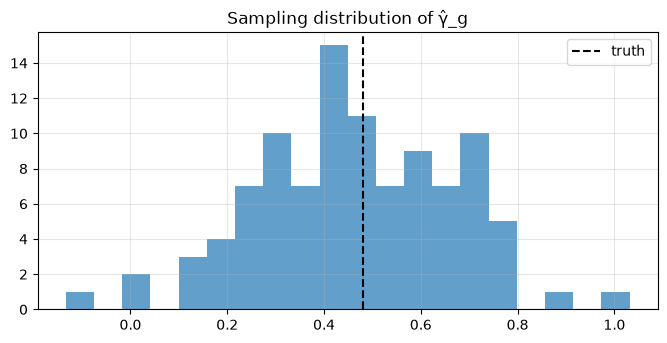

In [7]:
hits, estimates = [], []
for s in range(100):
    d = lfm.simulate_factor_returns(T=400, N=60, seed=500 + s)
    r = lfm.ThreePassRiskPremia(lfm.PCA(3)).fit(d.returns, d.observable[:, :1])
    estimates.append(r.gamma_g[0])
    hits.append(abs(r.gamma_g[0] - d.risk_premia[0]) <= 1.96 * r.se[0])
print(f"coverage of 95% CIs: {np.mean(hits):.2f}")
plt.hist(estimates, bins=20, alpha=0.7)
plt.axvline(d.risk_premia[0], color="k", ls="--", label="truth")
plt.legend()
plt.title("Sampling distribution of γ̂_g");

**Validation.** Identical to the authors' `PCAFM.m` for $\hat\gamma_g$, $\hat\gamma_0$,
variances, $R^2_g$, Wald tests and $\hat p$ (`docs/validation.md`).
**Related.** SPCA (notebook 03) is preferable when the factor is *weak* in the
test assets.